In [1]:
#
# Cell 1: import libraries
#


import numpy as np
from pathlib import Path
import pandas as pd


In [3]:
#
# Cell 2: define function "load_refined_brush_file" to load data
#

def load_refined_brush_file(fp: str | Path):
    data = np.load(Path(fp), allow_pickle=True)
    sentence = data[0]                 # string label
    drawing = data[1]                  # (N,3) float array
    x = drawing[:, 0]
    y = drawing[:, 1]
    eos = drawing[:, 2].astype(int)    # 0/1
    t = np.arange(len(drawing))        # implicit time index
    return sentence, x, y, eos, t

sentence, x, y, eos, t = load_refined_brush_file("D:/BRUSH/refined_BRUSH/BRUSH/130/2_resample25")
print(sentence, x.shape, np.unique(eos))

dwelling. Frankfurt (232,) [0 1]


In [5]:
#
# Cell 3: counts the number of folders on a diretory
#

# Source - https://stackoverflow.com/a/3883201
# Posted by Mark Byers, modified by community. See post 'Timeline' for change history
# Retrieved 2026-04-17, License - CC BY-SA 2.5

import os.path
path = 'D:/BRUSH/refined_BRUSH/BRUSH/100'
num_files = len([f for f in os.listdir(path)
                if os.path.isfile(os.path.join(path, f))])
num_files=int(num_files/3)
num_files

162

In [7]:
#
# Cell 4: defines the list "list_of_strings_to_extract" with strings to extract 
#

list_of_strings_to_extract = [
     'fulfilling Dylks',
    'gunpowder exclaim',
     'husbandman Jacques',
    'The quick brown fox',
    'smart squid who asks',
     'jumps over the lazy',
     'childish piecemeal',
     'microscope dusky', 
     'overpower lightsome',
      'Bagdad unrequited', 
      'recognize Boxer'
]
list_of_strings_to_extract    

['fulfilling Dylks',
 'gunpowder exclaim',
 'husbandman Jacques',
 'The quick brown fox',
 'smart squid who asks',
 'jumps over the lazy',
 'childish piecemeal',
 'microscope dusky',
 'overpower lightsome',
 'Bagdad unrequited',
 'recognize Boxer']

In [9]:
#
# Cell 5: counts the number of file in adirectory
#

import os, os.path#

# simple version for working with CWD
print(len([name for name in os.listdir('.') if os.path.isfile(name)]))
#
# path joining version for other paths
#DIR = '/tmp'
#print (len([name for name in os.listdir(DIR) if os.path.isfile(os.path.join(DIR, name))]))

75


In [13]:
#
# Cell 6: Extracts the data, print message, if file does not exist.
#

import time

start = time.time()

extracted_data_dict= {}
missing_file_list=[]
for j in range(170):
    directory_path_1 = f"D:/BRUSH/refined_BRUSH/BRUSH/1"
    num_files = len([name for name in os.listdir(directory_path_1) if os.path.isfile(os.path.join(directory_path_1, name)) if len(name) < 4])
    #print('num_files: ',num_files)
    for i in range(num_files):
        try:
            directory_path_2 = f"D:/BRUSH/refined_BRUSH/BRUSH/{j}/{i}"
            sentence, x, y, eos, t = load_refined_brush_file(directory_path_2)
            if sentence in list_of_strings_to_extract:
                if j not in extracted_data_dict:
                    extracted_data_dict[j] = {}

                #extracted_data_dict.update({'1':{i:{sentence: [x, y]}}})
                #extracted_data_dict.update({j:{sentence: [x, y]}})
                extracted_data_dict[j][sentence] = [x, y]
        except FileNotFoundError:
            print(f"For writer '{j}' file number '{i}' don't exist.")
            missing_file_list.append((j, i))

end = time.time()
print('time (min): ',(end - start)/60)

For writer '3' file number '132' don't exist.
For writer '3' file number '133' don't exist.
For writer '3' file number '134' don't exist.
For writer '3' file number '135' don't exist.
For writer '3' file number '136' don't exist.
For writer '3' file number '137' don't exist.
For writer '3' file number '138' don't exist.
For writer '3' file number '139' don't exist.
For writer '3' file number '140' don't exist.
For writer '3' file number '141' don't exist.
For writer '3' file number '142' don't exist.
For writer '3' file number '143' don't exist.
For writer '3' file number '144' don't exist.
For writer '3' file number '145' don't exist.
For writer '3' file number '146' don't exist.
For writer '3' file number '147' don't exist.
For writer '3' file number '148' don't exist.
For writer '3' file number '149' don't exist.
For writer '3' file number '150' don't exist.
For writer '3' file number '151' don't exist.
For writer '3' file number '152' don't exist.
For writer '3' file number '153' d

In [15]:
#
# Cell 7: only for analytical purpose; prints for all writers (1 to 170) the extractedd texts.
#


overview = {
    folder: list(inner_dict.keys())
    for folder, inner_dict in extracted_data_dict.items()
}

# print(overview)

In [17]:
#
# Cell 8: creates a folder for data storage.
#

# Specify the directory name
directory_path = Path("D:/ECG/handwriting")

# Create the directory
try:
    directory_path.mkdir()
    print(f"Directory '{directory_path}' created successfully.")
except FileExistsError:
    print(f"Directory '{directory_path}' already exists.")
except PermissionError:
    print(f"Permission denied: Unable to create '{directory_path}'.")
except Exception as e:
    print(f"An error occurred: {e}")
    

Directory 'D:\ECG\handwriting' already exists.


In [19]:
#
# Cell 9: Saves extracted_data_dict
#

import pickle

directory_path = Path("D:/ECG/handwriting")

with open(directory_path/'extracted_data_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(extracted_data_dict, f) # serialize the list
    f.close()



In [11]:
#
# Cell 10: load extracted_data_dict
#

import pickle

directory_path = Path("D:/ECG/handwriting")

with open(directory_path/'extracted_data_dict.pkl', 'rb') as f:
   extracted_data_dict = pickle.load(f) # deserialize using load()
f.close()  

#Y_final_dfs

In [13]:
#
# Cell 11: converts dictionary in dataframe
#


rows = []

for writer, sentences in extracted_data_dict.items():
    for sentence, (x, y) in sentences.items():
        rows.append({
            "writer": writer,
            "sentence": sentence,
            "x": x,
            "y": y
        })

extracted_data_df = pd.DataFrame(rows)

In [14]:
#
# Cell 12: for analytical purpose
#

extracted_data_df[0:2]

,writer,sentence,x,y
0,0,microscope dusky,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.445828914642334, 0...","[79.1444149017334, 79.3321590423584, 79.519903..."
1,0,overpower lightsome,"[0.0, 0.0, 0.6100940704345703, 1.1263122558593...","[79.53050994873047, 80.34743320240693, 81.2664..."


In [17]:
#
# Cell 13: copy 'writer' and 'sentence' columns from extracted_data_df
# = y_data_1
#


y_data_1 = extracted_data_df[['writer','sentence']].copy() 
y_data_1

,writer,sentence
0,0,microscope dusky
1,0,overpower lightsome
2,0,childish piecemeal
3,0,fulfilling Dylks
4,0,gunpowder exclaim
...,...,...
1749,169,Bagdad unrequited
1750,169,recognize Boxer
1751,169,The quick brown fox
1752,169,jumps over the lazy


In [19]:
#
# Cell 14: ONE LABEL - count number of each sentence in column "sentence" 
#

combo_counts = y_data_1["sentence"].value_counts()
combo_counts

#combo_counts.to_csv("combo_counts.csv")

sentence
microscope dusky        165
The quick brown fox     165
overpower lightsome     162
jumps over the lazy     162
smart squid who asks    161
gunpowder exclaim       160
recognize Boxer         157
childish piecemeal      156
husbandman Jacques      156
Bagdad unrequited       156
fulfilling Dylks        154
Name: count, dtype: int64

In [21]:
#
# Cell 15: makes a dictionary from list list_of_strings_to_extract
#

dfs= {}
for item in list_of_strings_to_extract:
    #dfs['Y_'+item] = item
    dfs[item] = item
dfs

{'fulfilling Dylks': 'fulfilling Dylks',
 'gunpowder exclaim': 'gunpowder exclaim',
 'husbandman Jacques': 'husbandman Jacques',
 'The quick brown fox': 'The quick brown fox',
 'smart squid who asks': 'smart squid who asks',
 'jumps over the lazy': 'jumps over the lazy',
 'childish piecemeal': 'childish piecemeal',
 'microscope dusky': 'microscope dusky',
 'overpower lightsome': 'overpower lightsome',
 'Bagdad unrequited': 'Bagdad unrequited',
 'recognize Boxer': 'recognize Boxer'}

In [23]:
#
# Cell 16: splitts the set of all single labels into indiviual sets
#


individual_dfs = {
    name: y_data_1[y_data_1['sentence'] == sentence].copy()
    for name, sentence in dfs.items()
}

individual_dfs['husbandman Jacques']

,writer,sentence
5,0,husbandman Jacques
16,1,husbandman Jacques
27,2,husbandman Jacques
36,3,husbandman Jacques
46,4,husbandman Jacques
...,...,...
1704,165,husbandman Jacques
1715,166,husbandman Jacques
1726,167,husbandman Jacques
1737,168,husbandman Jacques


In [65]:
#
# Cell 17: splits the df in the dictionary "individual_dfs" in training, 
# validation and test sets.
#

# ----------------------------
# Training: 75%
# ----------------------------
training_dfs = {
    name: df.sample(frac=0.75, random_state=7).copy()
    for name, df in individual_dfs.items()
}

# ----------------------------
# Remaining: 25%
# ----------------------------
remaining_dfs = {
    name: df.drop(training_dfs[name].index).copy()
    for name, df in individual_dfs.items()
}

# ----------------------------
# Validation: 15% of original
# = 15/25 = 0.6 of remaining
# ----------------------------
validation_dfs = {
    name: remaining_dfs[name].sample(frac=0.60, random_state=7).copy()
    for name in individual_dfs
}

# ----------------------------
# Test: remaining 10%
# ----------------------------
test_dfs = {
    name: remaining_dfs[name].drop(validation_dfs[name].index).copy()
    for name in individual_dfs
}

display(training_dfs['husbandman Jacques'])

print(len(training_dfs['husbandman Jacques']))
print(len(validation_dfs['husbandman Jacques']))
print(len(test_dfs['husbandman Jacques']))

,writer,sentence
1029,99,husbandman Jacques
873,84,husbandman Jacques
436,42,husbandman Jacques
125,12,husbandman Jacques
807,78,husbandman Jacques
...,...,...
818,79,husbandman Jacques
1726,167,husbandman Jacques
1600,155,husbandman Jacques
1066,103,husbandman Jacques


117
23
16


In [27]:
#
# Cell 18: count the number of instances in all dictionary sets.
#

dfs_all= {1: test_dfs,
          2: training_dfs,
          3: validation_dfs
         }

summation=sum(df.shape[0] for df in dfs_all.values() for df in df.values())
print('Total sum of all instances in the different sets: ',summation)

Total sum of all instances in the different sets:  1754


In [67]:
#
# Cell 19: combine and shuffle all test / validation / training sets of all sets (all classes built)
#

train_df = pd.concat(training_dfs.values(), axis=0).sample(frac=1, random_state=7)
val_df   = pd.concat(validation_dfs.values(), axis=0).sample(frac=1, random_state=7)
test_df  = pd.concat(test_dfs.values(), axis=0).sample(frac=1, random_state=7)
train_df

,writer,sentence
1073,104,overpower lightsome
1249,120,The quick brown fox
483,47,fulfilling Dylks
1662,161,Bagdad unrequited
1437,138,The quick brown fox
...,...,...
817,79,gunpowder exclaim
141,13,smart squid who asks
867,83,smart squid who asks
743,72,recognize Boxer


In [69]:
#
# Cell 20: collect all df in a dictionary
#

Y_final_dfs = {'train_df' : train_df, 'val_df': val_df, 'test_df' : test_df}

## following cells for X-data manipulation

In [33]:
#
# Cell 21: converts the y-coordinates of the handwritten text into a numpy array
#

X_data = extracted_data_df['y'].to_numpy()

In [35]:
#
# Cell 22: for analytical purpose only
#

print(len(X_data[0]))
print(len(X_data[1]))      

537
478


In [37]:
#
# Cell 23: defines function "extend_to_1000" to extend all the arrays 
# of different length (see previous cell) to one common length of 1000 datapoint. 
# the existing datapoint will be added again until at least 1000 datapoint are reached.
#


def extend_to_1000(arr):
    arr = np.asarray(arr)
    n = len(arr)

    if n == 0:
        return np.zeros(1000)  # or raise an error

    repeats = int(np.ceil(1000 / n))
    extended = np.tile(arr, repeats)

    return extended[:1000]

In [38]:
#
# Cell 24: applies function "extend_to_1000" to X_data  
#


X_data_1000 = np.array(
    [extend_to_1000(y_arr) for y_arr in X_data]
)

In [41]:
#
# Cell 25: for analytical purpose only
#

X_data_1000.shape

(1754, 1000)

In [43]:
#
# Cell 26:centers the data around the mean value 
#

# Compute the mean of each row (shape: (n_samples, 1))
row_means = np.mean(X_data_1000, axis=1, keepdims=True)

# Center each row around its own mean
X_data_1000_centered = X_data_1000 - row_means


In [45]:
#
# Cell 27: for analytical purpose only 
#

print(np.allclose(np.mean(X_data_1000_centered, axis=1), 0))

True


In [47]:
#
# Cell 28: scaling the range of y-coordinate data of sentences approximatelly 
# to the range of the ECG x-data (about 1), see module "min_max_of_X_data.ipynb"
# the "scaling_factor" is an empirical factor, depending on resultsof cell 29 
#

scaling_factor = 0.4

X_data_centered_scaled = X_data_1000_centered/((np.max(X_data_1000_centered)-np.min(X_data_1000_centered))*scaling_factor)


In [49]:
#
# Cell 29: check the scaling result 
#

max_element_row = np.max(X_data_centered_scaled, 1)
min_element_row = np.amin(X_data_centered_scaled, 1)

print('maximum elements in the rows of the array is:', 
      max_element_row)
print('minimum elements in the rows of the array is:',
      min_element_row)
##########
max_max_element_row = np.max(max_element_row)
min_max_element_row = np.amin(max_element_row)

print('maximum element in the row is:', 
      max_max_element_row)
print('minimum element in the row is:',
      min_max_element_row)

##############
mean_max_element_row = np.mean(max_element_row)

print('mean element in the row is:', 
      mean_max_element_row)

################
max_min_element_row = np.max(min_element_row)
min_min_element_row = np.amin(min_element_row)

print('maximum element in the row is:', 
      max_min_element_row)
print('minimum element in the row is:',
      min_min_element_row)
###############
mean_min_element_row = np.mean(min_element_row)

print('mean element in the row is:', 
      mean_min_element_row)


maximum elements in the rows of the array is: [0.47575    0.43270033 0.41608672 ... 0.54529182 0.53941157 0.4581775 ]
minimum elements in the rows of the array is: [-0.52520542 -0.43925134 -0.39886021 ... -0.46866644 -0.37739714
 -0.41090891]
maximum element in the row is: 1.5220445237536817
minimum element in the row is: 0.12127320789044863
mean element in the row is: 0.4555185643884681
maximum element in the row is: -0.1489440956004449
minimum element in the row is: -0.9779554762463181
mean element in the row is: -0.4094367333246662


In [51]:
#
# Cell 30: save recaled y-coordinates to "X" 
#

X = X_data_centered_scaled.copy()

In [53]:
#
# Cell 31: for analytical purpose only 
#

y_for_graph=X[0]


## x-data manipulation ends

In [71]:
#
# Cell 32: separets X values in training-, validation- and test data.
#

X_train = X[train_df.index.tolist(), :]
X_val   = X[val_df.index.tolist(), :]
X_test  = X[test_df.index.tolist(), :]

In [73]:
#
# Cell 31: add one dimension to the x-data; 
# purpose: align with the datastructure of the ECG x-data   
#

X_train_12 = np.repeat(
    X_train[:, :, np.newaxis],
    repeats=12,
    axis=2
)

X_val_12 = np.repeat(
    X_val[:, :, np.newaxis],
    repeats=12,
    axis=2
)

X_test_12 = np.repeat(
    X_test[:, :, np.newaxis],
    repeats=12,
    axis=2
)

In [75]:
#
# Cell 32: creates a folder for data storage.
#

# Specify the directory name
directory_path = Path("D:/ECG/handwriting")

# Create the directory
try:
    directory_path.mkdir()
    print(f"Directory '{directory_path}' created successfully.")
except FileExistsError:
    print(f"Directory '{directory_path}' already exists.")
except PermissionError:
    print(f"Permission denied: Unable to create '{directory_path}'.")
except Exception as e:
    print(f"An error occurred: {e}")

Directory 'D:\ECG\handwriting' already exists.


In [77]:
#
# Cell 33: stores the X data (numpy arrays) to archive in the created folder    
#

np.savez(directory_path/'X_hwrtng_np_arrays_3.npz', a = X_train_12, b = X_val_12, c = X_test_12)

In [79]:
#
# Cell 34: Saves Y_final_dfs and X_final_dfs
#

import pickle

with open(directory_path/'Y_hwrtng_data_3.pkl', 'wb') as f:  # open a text file
    pickle.dump(Y_final_dfs, f) # serialize the list
    f.close()

## End of data preparation
## Start of data visualization

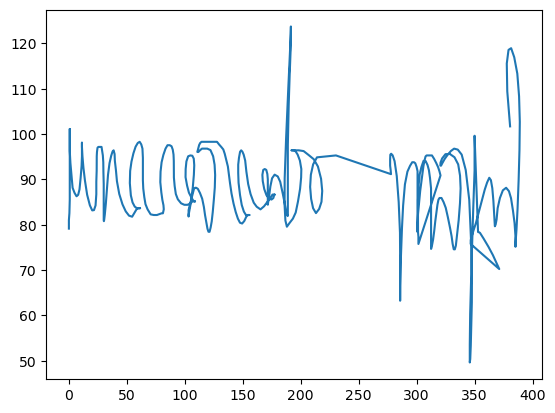

In [37]:
import matplotlib.pyplot as plt

x_axis_data=x
y_axis_data=y

plt.plot(x_axis_data, y_axis_data)


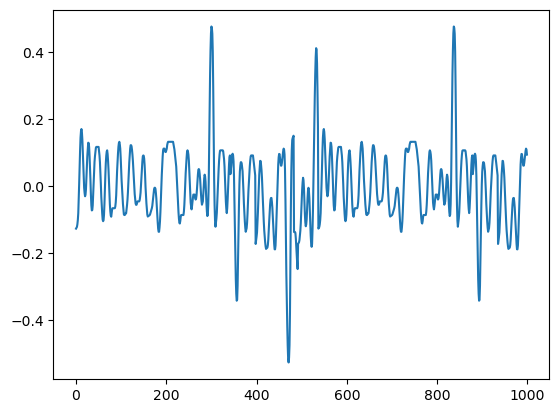

In [68]:
#x_axis_data=x
import matplotlib.pyplot as plt

y_axis_data=y_for_graph

plt.plot(y_axis_data)
